# Tarea 1 · Parte 1 — Recolección de noticias de La República

> **Pregunta guía:** ¿Pueden convertir titulares peruanos en un clasificador de noticias?

Este notebook construye el dataset `datos/noticias.csv`: titulares reales de La República con su
bajada, sección, URL, fecha y una **etiqueta estandarizada** en una de las 4 categorías del curso.

## Configuración inicial

| Campo | Valor |
|---|---|
| **Medio elegido** | La República — Opción A (`larepublica.pe`) |
| **Fecha de descarga** | 18 de octubre de 2026 (la hora exacta queda registrada en `datos/raw/metadatos_descarga.json`) |
| **URL base** | https://larepublica.pe |
| **Reglas del sitio** | https://larepublica.pe/robots.txt |
| **RSS oficiales** | https://larepublica.pe/rss/politica.xml · https://larepublica.pe/rss/economia.xml · https://larepublica.pe/rss/deportes.xml · https://larepublica.pe/rss/ciencia.xml · https://larepublica.pe/rss/home.xml |
| **Páginas de sección (HTML)** | https://larepublica.pe/politica · https://larepublica.pe/economia · https://larepublica.pe/deportes · https://larepublica.pe/ciencia · https://larepublica.pe/tecnologia |
| **Categorías finales** | `politica`, `economia`, `deportes`, `ciencia_tecnologia` |
| **Meta** | ~100 noticias por categoría (mínimo 350 en total) |

**Estrategia.** Primero los canales RSS oficiales; como solo cubren las últimas ~48 horas, se completan
con el HTML de las páginas de sección y de cada noticia (ambas rutas permitidas por `robots.txt`).
Se aplican las tres reglas del scraping de la sesión 4: identificarse con un `User-Agent`, no saturar
el sitio (pausa de 1 a 2 segundos y como máximo 1 reintento) y **guardar apenas se extrae**
(respaldo crudo en `datos/raw/`).

## 0 · Preparación

In [1]:
import json
import random
import re
import time
from collections import Counter, deque
from datetime import datetime
from pathlib import Path
from urllib.parse import urlparse

import pandas as pd
import plotly.express as px
import plotly.io as pio
import requests
from bs4 import BeautifulSoup

# Cada gráfico se guarda interactivo (VS Code / Jupyter) y también como PNG,
# porque GitHub solo muestra la imagen estática al abrir el notebook.
pio.renderers.default = "plotly_mimetype+png"
pio.renderers["png"].width, pio.renderers["png"].height = 950, 520
pd.set_option("display.max_colwidth", 110)
random.seed(42)

DATOS = Path("datos")
RAW = DATOS / "raw"
RAW.mkdir(parents=True, exist_ok=True)

MEDIO = "La Republica"
BASE = "https://larepublica.pe"
# El User-Agent identifica quién hace la consulta (sesión 4).
HEADERS = {"User-Agent": "Mozilla/5.0 (compatible; TareaAcademica/1.0; "
                         "Diplomado PUCP - curso Python Intermedio para CCSS)"}

# Secciones del diario que alimentan cada categoría. Las subsecciones heredan de su sección
# madre (economia/precio-del-dolar -> economia). Todo lo demás se descarta en la limpieza.
MAPEO = {
    "politica": "politica",
    "economia": "economia",
    "deportes": "deportes",
    "ciencia": "ciencia_tecnologia",
    "tecnologia": "ciencia_tecnologia",
}
CATEGORIAS = ["politica", "economia", "deportes", "ciencia_tecnologia"]
META_POR_CATEGORIA = 100

# Si el respaldo crudo ya existe, no se vuelve a pedir nada a la web.
DESCARGAR = not (RAW / "noticias_crudas.csv").exists()
print("¿Descargar de la web?", DESCARGAR)

¿Descargar de la web? True


## 1 · Leer y respetar `robots.txt`

Antes de pedir cualquier página se revisa qué rutas prohíbe el diario. El archivo se guarda en
`datos/raw/` como evidencia.

In [2]:
archivo_robots = RAW / "robots.txt"
if not archivo_robots.exists():
    r = requests.get(f"{BASE}/robots.txt", headers=HEADERS, timeout=30)
    r.raise_for_status()
    archivo_robots.write_text(r.text, encoding="utf-8")
robots = archivo_robots.read_text(encoding="utf-8")

def reglas(tipo):
    return [l.split(":", 1)[1].strip() for l in robots.splitlines()
            if l.lower().startswith(tipo + ":") and l.split(":", 1)[1].strip()]

prohibidas, permitidas = reglas("disallow"), reglas("allow")
print(f"{len(prohibidas)} rutas prohibidas, p. ej.: {prohibidas[:9]}")
print(f"Rutas permitidas explícitamente: {permitidas}")

22 rutas prohibidas, p. ej.: ['/buscador*', '/data', '/data/*', '/contactenos', '/*/pag/', '/*/pag/*', '/*/*/page/*', '/archive/*', '/archivo/*']
Rutas permitidas explícitamente: ['/sitemap/', '/sitemap/*', '/sitemaps/*', '/rss/', '/rss/*']


`robots.txt` usa comodines (`*`). Se traducen a expresiones regulares para poder preguntar, antes de
cada pedido, si la ruta está permitida. Nótese que **la paginación (`/pag/`) y el archivo histórico
(`/archivo/`) están prohibidos**, así que no se usan; RSS y sitemaps están permitidos de forma
explícita y las páginas de noticia no están en ninguna regla de exclusión.

In [3]:
patrones_prohibidos = [re.compile(re.escape(p).replace(r"\*", ".*")) for p in prohibidas]

def permitido(url):
    ruta = urlparse(url).path
    return not any(rx.match(ruta) for rx in patrones_prohibidos)

for url in [f"{BASE}/rss/politica.xml",
            f"{BASE}/politica",
            f"{BASE}/politica/2026/10/18/una-noticia-cualquiera-123",
            f"{BASE}/politica/pag/2",
            f"{BASE}/archivo/2026"]:
    print(f"{'permitido ' if permitido(url) else 'PROHIBIDO '} {url}")

permitido  https://larepublica.pe/rss/politica.xml
permitido  https://larepublica.pe/politica
permitido  https://larepublica.pe/politica/2026/10/18/una-noticia-cualquiera-123
PROHIBIDO  https://larepublica.pe/politica/pag/2
PROHIBIDO  https://larepublica.pe/archivo/2026


## 2 · Extracción

### 2.1 · Una sola función para pedir páginas

Todos los pedidos pasan por `pedir()`: verifica `robots.txt`, se identifica con el `User-Agent`,
espera entre 1 y 2 segundos después de cada pedido y reintenta **como máximo una vez**. Un `404` o
`410` no se reintenta: la página no existe.

In [4]:
n_pedidos = 0

def pedir(url, reintentos=1):
    global n_pedidos
    if not permitido(url):
        print("   robots.txt no lo permite:", url)
        return None
    for intento in range(reintentos + 1):
        try:
            r = requests.get(url, headers=HEADERS, timeout=30)
            n_pedidos += 1
            time.sleep(random.uniform(1, 2))            # no saturar el sitio
            if r.status_code == 200:
                return r
            print(f"   HTTP {r.status_code} · {url}")
            if r.status_code in (404, 410):              # no existe: reintentar no sirve
                return None
        except requests.exceptions.RequestException as e:
            print(f"   falló ({type(e).__name__}) · {url}")
            time.sleep(random.uniform(1, 2))
    return None

### 2.2 · Canal oficial: RSS

Se leen los RSS de las secciones objetivo y el de portada (`home`). El de portada trae noticias de
**todas** las secciones: sirve para ver qué se descarta en la limpieza. También se pide el de
`tecnologia` para documentar si existe.

In [5]:
FEEDS = ["politica", "economia", "deportes", "ciencia", "tecnologia", "home"]

def texto(nodo):
    return nodo.get_text(strip=True) if nodo else ""

def leer_rss(nombre):
    archivo = RAW / f"rss_{nombre}.xml"
    if archivo.exists():
        contenido = archivo.read_bytes()
    else:
        r = pedir(f"{BASE}/rss/{nombre}.xml")
        if r is None:
            return []
        contenido = r.content
        archivo.write_bytes(contenido)                   # se guarda apenas se extrae
    sopa = BeautifulSoup(contenido, "xml")
    return [{
        "url": texto(item.link),
        "titular": texto(item.title),
        "bajada": texto(item.description),
        "categoria_web": texto(item.category),
        "fecha": texto(item.pubDate),
        "fuente": f"rss:{nombre}",
    } for item in sopa.find_all("item")]

rss = []
for nombre in FEEDS:
    filas = leer_rss(nombre)
    print(f"rss/{nombre + '.xml':<16} {len(filas):>3} noticias")
    rss.extend(filas)

rss/politica.xml      22 noticias


rss/economia.xml       6 noticias


rss/deportes.xml      14 noticias


rss/ciencia.xml       10 noticias


   HTTP 410 · https://larepublica.pe/rss/tecnologia.xml
rss/tecnologia.xml     0 noticias


rss/home.xml         200 noticias


In [6]:
rss_df = pd.DataFrame(rss)
rss_df["publicado"] = pd.to_datetime(rss_df["fecha"], utc=True).dt.tz_convert("America/Lima")
resumen_rss = rss_df.groupby("fuente").agg(
    noticias=("url", "size"),
    desde=("publicado", "min"),
    hasta=("publicado", "max"),
)
resumen_rss["horas_cubiertas"] = ((resumen_rss["hasta"] - resumen_rss["desde"])
                                  .dt.total_seconds() / 3600).round(1)
resumen_rss

,noticias,desde,hasta,horas_cubiertas
fuente,,,,
rss:ciencia,10,2026-10-16 22:48:22-05:00,2026-10-18 19:32:25-05:00,44.7
rss:deportes,14,2026-10-16 21:45:00-05:00,2026-10-18 20:36:45-05:00,46.9
rss:economia,6,2026-10-17 14:26:30-05:00,2026-10-18 20:33:00-05:00,30.1
rss:home,200,2026-10-16 21:29:22-05:00,2026-10-18 20:55:51-05:00,47.4
rss:politica,22,2026-10-16 21:36:16-05:00,2026-10-18 20:12:42-05:00,46.6


**Diagnóstico.** Los RSS funcionan, pero cada canal solo trae lo publicado en las últimas ~48 horas
(unas decenas de noticias en total) y `tecnologia` no tiene RSS. Con eso no se llega a ~100 por
categoría. Como el diario **no bloquea** el HTML y `robots.txt` permite las páginas de sección y de
noticia, se completa con HTML (`requests` + `BeautifulSoup`).

### 2.3 · Completar con HTML: páginas de sección y de noticia

Cada página de noticia trae, además de sus propios datos, enlaces a otras noticias de su misma
sección (incluidas algunas más antiguas). Eso permite avanzar de noticia en noticia sin usar la
paginación prohibida:

1. Las páginas de sección (`/politica`, `/economia`, …) dan los primeros enlaces.
2. Se abre una noticia, se extraen sus datos y se guardan **en ese instante** en
   `datos/raw/articulos_html.jsonl` (una línea por noticia).
3. Sus enlaces a otras noticias de las secciones objetivo pasan a la cola.
4. Siempre se atiende primero a la categoría con menos noticias, hasta llegar a la meta.

De cada noticia se lee: el `<h1>` (titular), `og:description` (bajada), `og:category` (sección según
el diario) y `datePublished` del bloque JSON-LD (fecha). La sección sale de la propia URL.

In [7]:
PATRON_NOTICIA = re.compile(
    r"^https://larepublica\.pe/(?P<seccion>[a-z0-9\-]+(?:/[a-z0-9\-]+)*?)"
    r"/(?P<fecha>20\d\d/\d\d/\d\d)/[a-z0-9\-]+$"
)

def normalizar_url(u):
    u = u.split("?")[0].split("#")[0].rstrip("/")
    return BASE + u if u.startswith("/") else u

def seccion_de(url):
    m = PATRON_NOTICIA.match(url)
    return m.group("seccion") if m else None

def categoria_de(url):
    seccion = seccion_de(url)
    return MAPEO.get(seccion.split("/")[0]) if seccion else None

def enlaces_noticias(sopa):
    urls = {normalizar_url(a["href"]) for a in sopa.find_all("a", href=True)}
    return {u for u in urls if seccion_de(u)}

def leer_noticia(url):
    r = pedir(url)
    if r is None:
        return None, set()
    sopa = BeautifulSoup(r.text, "html.parser")

    def meta(clave):
        tag = sopa.find("meta", attrs={"property": clave}) or sopa.find("meta", attrs={"name": clave})
        return tag.get("content", "").strip() if tag else ""

    publicado = ""
    for bloque in sopa.find_all("script", type="application/ld+json"):
        try:
            datos = json.loads(bloque.string or "")
        except json.JSONDecodeError:
            continue
        for x in datos if isinstance(datos, list) else [datos]:
            if isinstance(x, dict) and x.get("datePublished"):
                publicado = x["datePublished"]

    h1 = sopa.find("h1")
    registro = {
        "url": url,
        "titular": re.sub(r"\s+", " ", h1.get_text()).strip() if h1 else meta("og:title"),
        "bajada": meta("og:description") or meta("description"),
        "categoria_web": meta("og:category"),
        "fecha": publicado,
        "fuente": "html",
        "descargado": datetime.now().astimezone().isoformat(timespec="seconds"),
    }
    return registro, enlaces_noticias(sopa)

# Prueba con una noticia del RSS antes de recorrer cientos (regla de la sesión 5: probar con poco)
if DESCARGAR:
    prueba, enlaces_prueba = leer_noticia(normalizar_url(rss[0]["url"]))
    print(json.dumps(prueba, ensure_ascii=False, indent=1))
    print(f"enlaces a otras noticias en esa página: {len(enlaces_prueba)}")

{
 "url": "https://larepublica.pe/politica/2026/10/18/keiko-fujimori-coordina-con-delcy-rodriguez-la-expulsion-de-venezolanos-indocumentados-hnews-1255032",
 "titular": "Keiko Fujimori coordinó con Delcy Rodríguez la expulsión de venezolanos indocumentados",
 "bajada": "La mandataria informó que su Gobierno iniciará el apoyo al programa Vuelta a la Patria, iniciativa venezolana orientada al retorno de sus ciudadanos a su país de origen.",
 "categoria_web": "Política",
 "fecha": "2026-10-18T20:12:42-05:00",
 "fuente": "html",
 "descargado": "2026-10-18T21:02:46-05:00"
}
enlaces a otras noticias en esa página: 31


In [8]:
ARCHIVO_HTML = RAW / "articulos_html.jsonl"
MAX_PEDIDOS = 650          # tope de seguridad

if DESCARGAR:
    inicio = time.perf_counter()
    urls_rss = {normalizar_url(f["url"]) for f in rss}
    html = ([json.loads(l) for l in ARCHIVO_HTML.open(encoding="utf-8")]
            if ARCHIVO_HTML.exists() else [])               # si se cortó antes, se retoma
    capturadas = urls_rss | {h["url"] for h in html}
    intentadas = {h["url"] for h in html}
    conteo = Counter(categoria_de(u) for u in capturadas)

    frontera = {c: deque() for c in CATEGORIAS}
    # Noticias que ya vinieron por RSS: solo se abren si una categoría se queda sin enlaces
    semillas = {c: deque(sorted(u for u in urls_rss if categoria_de(u) == c)) for c in CATEGORIAS}

    def encolar(enlaces):
        for u in enlaces:
            c = categoria_de(u)
            if c and u not in capturadas:
                frontera[c].append(u)

    for seccion in MAPEO:
        r = pedir(f"{BASE}/{seccion}")
        if r is not None:
            encolar(enlaces_noticias(BeautifulSoup(r.text, "html.parser")))
    print("Enlaces iniciales por categoría:", {c: len(f) for c, f in frontera.items()})
    print("Ya capturadas por RSS:", {c: conteo[c] for c in CATEGORIAS})

    with ARCHIVO_HTML.open("a", encoding="utf-8") as salida:
        while n_pedidos < MAX_PEDIDOS:
            pendientes = [c for c in CATEGORIAS
                          if conteo[c] < META_POR_CATEGORIA and (frontera[c] or semillas[c])]
            if not pendientes:
                break
            c = min(pendientes, key=lambda k: conteo[k])
            url = frontera[c].popleft() if frontera[c] else semillas[c].popleft()
            if url in intentadas:
                continue
            intentadas.add(url)
            registro, enlaces = leer_noticia(url)
            encolar(enlaces)
            if registro is None:
                continue
            salida.write(json.dumps(registro, ensure_ascii=False) + "\n")
            salida.flush()                                   # se guarda apenas se extrae
            html.append(registro)
            if url not in capturadas:
                capturadas.add(url)
                conteo[c] += 1
            if len(html) % 50 == 0:
                print(f"  {len(html):>3} páginas leídas · {n_pedidos} pedidos · "
                      f"{time.perf_counter() - inicio:5.0f} s · {dict(conteo)}")

    duracion = time.perf_counter() - inicio
    print(f"\nListo: {len(html)} páginas de noticia, {n_pedidos} pedidos en {duracion / 60:.1f} min")
    print("Noticias únicas por categoría (RSS + HTML):", {c: conteo[c] for c in CATEGORIAS})

Enlaces iniciales por categoría: {'politica': 5, 'economia': 7, 'deportes': 0, 'ciencia_tecnologia': 12}
Ya capturadas por RSS: {'politica': 22, 'economia': 6, 'deportes': 14, 'ciencia_tecnologia': 10}


   50 páginas leídas · 62 pedidos ·   143 s · {'economia': 25, None: 148, 'politica': 26, 'deportes': 25, 'ciencia_tecnologia': 25}


  100 páginas leídas · 112 pedidos ·   300 s · {'economia': 38, None: 148, 'politica': 38, 'deportes': 38, 'ciencia_tecnologia': 37}


  150 páginas leídas · 162 pedidos ·   449 s · {'economia': 50, None: 148, 'politica': 51, 'deportes': 50, 'ciencia_tecnologia': 50}


  200 páginas leídas · 212 pedidos ·   604 s · {'economia': 63, None: 148, 'politica': 63, 'deportes': 63, 'ciencia_tecnologia': 62}


  250 páginas leídas · 262 pedidos ·   758 s · {'economia': 75, None: 148, 'politica': 76, 'deportes': 75, 'ciencia_tecnologia': 75}


  300 páginas leídas · 312 pedidos ·   919 s · {'economia': 88, None: 148, 'politica': 88, 'deportes': 88, 'ciencia_tecnologia': 87}


   HTTP 404 · https://larepublica.pe/politica/2026/10/05/muere-en-venezuela-mujer-implicada-en-crimen-de-china-polo-alexandra-toro-montezuma-susy-aponte-polo-ronald-toro-ar



Listo: 349 páginas de noticia, 362 pedidos en 18.0 min
Noticias únicas por categoría (RSS + HTML): {'politica': 100, 'economia': 100, 'deportes': 100, 'ciencia_tecnologia': 100}


### 2.4 · Respaldo crudo

Se juntan las dos fuentes **sin limpiar nada** y se guardan en `datos/raw/noticias_crudas.csv`,
junto con los metadatos de la descarga. A partir de aquí todo se puede rehacer sin volver a pedir
nada a la web.

In [9]:
if DESCARGAR:
    crudo = pd.concat([pd.DataFrame(rss), pd.DataFrame(html)], ignore_index=True)
    crudo.to_csv(RAW / "noticias_crudas.csv", index=False)
    (RAW / "metadatos_descarga.json").write_text(json.dumps({
        "medio": MEDIO,
        "fecha_descarga": datetime.now().astimezone().isoformat(timespec="seconds"),
        "pedidos_http": n_pedidos,
        "user_agent": HEADERS["User-Agent"],
        "pausa_entre_pedidos_s": [1, 2],
        "reintentos_max": 1,
        "feeds_rss": FEEDS,
    }, ensure_ascii=False, indent=2), encoding="utf-8")

crudo = pd.read_csv(RAW / "noticias_crudas.csv", keep_default_na=False)
metadatos = json.loads((RAW / "metadatos_descarga.json").read_text(encoding="utf-8"))
print("Descarga:", metadatos["fecha_descarga"], "·", metadatos["pedidos_http"], "pedidos HTTP")
print("Filas crudas:", crudo.shape)
crudo["fuente"].value_counts()

Descarga: 2026-10-18T21:20:45-05:00 · 362 pedidos HTTP
Filas crudas: (601, 7)


fuente
html            349
rss:home        200
rss:politica     22
rss:deportes     14
rss:ciencia      10
rss:economia      6
Name: count, dtype: int64

Se hicieron **362 pedidos HTTP en 18 minutos** (≈ 3 s por pedido, incluida la pausa). Solo una página respondió `404` (una nota retirada por el diario) y se descartó sin reintentar. Ningún pedido fue bloqueado (`403`/`429`).

## 3 · Limpieza y normalización

### 3.1 · Texto, fecha y sección

* Espacios repetidos fuera de titular y bajada.
* La fecha llega en dos formatos (RSS en GMT: `Mon, 19 Oct 2026 01:12:42 GMT`; HTML con zona
  horaria: `2026-10-16T18:38:03-05:00`). Se pasa todo a **hora de Lima** y a `AAAA-MM-DD`; si
  faltara, se usa la fecha que trae la URL.
* `seccion_original` es la sección tal como figura en la URL del diario (por ejemplo, `politica` o
  `economia/precio-del-dolar`).

In [10]:
df = crudo.copy()
df["url"] = df["url"].map(normalizar_url)
for col in ["titular", "bajada"]:
    df[col] = df[col].fillna("").astype(str).str.replace(r"\s+", " ", regex=True).str.strip()

fecha = pd.to_datetime(df["fecha"], utc=True, errors="coerce", format="mixed")
df["fecha"] = fecha.dt.tz_convert("America/Lima").dt.strftime("%Y-%m-%d")
fecha_url = df["url"].str.extract(r"/(20\d\d)/(\d\d)/(\d\d)/").agg("-".join, axis=1)
df["fecha"] = df["fecha"].fillna(fecha_url)

df["seccion_original"] = df["url"].map(seccion_de)
df["medio"] = MEDIO
print("Fechas sin dato:", df["fecha"].isna().sum(), "· URLs que no son noticia:", df["seccion_original"].isna().sum())
df[["fuente", "seccion_original", "fecha", "titular"]].sample(5, random_state=1)

Fechas sin dato: 0 · URLs que no son noticia: 0


,fuente,seccion_original,fecha,titular
446,html,economia,2026-09-14,ONP y AFP: ¿qué pasa con tus aportes si cambias de sistema desde junio de 2027?
404,html,tecnologia,2023-02-06,¿Por qué no debes instalar Clean Master u otros limpiadores en tu teléfono? Aquí la respuesta
509,html,politica,2026-09-16,Comandante General Fredy López Mendoza publica sus primeros lineamientos como nuevo jefe de la PNP
455,html,deportes,2021-05-08,¿A qué hora juegan Atlético de Madrid vs. Barcelona por la fecha 35 de LaLiga?
201,rss:home,cine-series,2026-10-17,"'Bleach: Thousand-Year Blood War', temporada 4: ¿cuándo sale y a qué hora ver el capítulo 9?"


### 3.2 · Duplicados y titulares vacíos

Se descarta en este orden y se lleva la cuenta de cada motivo:

1. **Titular vacío o URL que no es una noticia.**
2. **URL duplicada**: la misma noticia llegó por dos caminos (p. ej., el RSS de sección y el de
   portada, o el RSS y la página HTML). Se conserva la primera aparición: el RSS oficial va primero.
3. **Titular duplicado** con otra URL (la misma nota republicada).

In [11]:
descartes = []

def descartar(mascara, motivo):
    global df
    descartes.append({"motivo": motivo, "noticias": int(mascara.sum()),
                      "ejemplo": df.loc[mascara, "titular"].head(1).str[:80].tolist()})
    df = df[~mascara].copy()

descartar((df["titular"] == "") | df["seccion_original"].isna(), "Titular vacío o URL que no es noticia")
descartar(df.duplicated("url", keep="first"), "URL duplicada (llegó por RSS y/o HTML más de una vez)")
descartar(df.duplicated("titular", keep="first"), "Titular duplicado con otra URL")
print("Quedan", len(df), "noticias únicas")

Quedan 547 noticias únicas


### 3.3 · Mapeo explícito: `seccion_original` → `etiqueta`

La etiqueta sale de la **sección editorial** del diario. Cada subsección hereda la etiqueta de su
sección madre; las secciones que no encajan en ninguna de las 4 categorías (sociedad, mundo,
espectáculos, etc.) **se descartan** — no se inventa una quinta categoría.

In [12]:
df["seccion_madre"] = df["seccion_original"].str.split("/").str[0]
df["etiqueta"] = df["seccion_madre"].map(MAPEO)

equivalencias = (
    df.groupby(["seccion_original", "seccion_madre"], dropna=False).size().rename("noticias").reset_index()
    .assign(etiqueta=lambda t: t["seccion_madre"].map(MAPEO).fillna("— descartada (fuera de las 4 categorías)"))
    .sort_values(["etiqueta", "noticias"], ascending=[True, False])
    [["seccion_original", "etiqueta", "noticias"]]
    .reset_index(drop=True)
)
equivalencias

,seccion_original,etiqueta,noticias
0,ciencia,ciencia_tecnologia,44
1,tecnologia,ciencia_tecnologia,31
2,tecnologia/smartphone,ciencia_tecnologia,19
3,tecnologia/actualidad,ciencia_tecnologia,4
4,tecnologia/tutoriales,ciencia_tecnologia,1
5,deportes,deportes,99
6,deportes/beisbol,deportes,1
7,economia,economia,82
8,economia/precio-del-dolar,economia,18
9,politica,politica,100


In [13]:
descartar(df["etiqueta"].isna(), "Sección fuera de las 4 categorías")

reporte = pd.DataFrame(descartes)
reporte.loc[len(reporte)] = {"motivo": "TOTAL descartadas", "noticias": reporte["noticias"].sum(), "ejemplo": []}
print(f"Filas crudas: {len(crudo)} → descartadas: {reporte['noticias'].iloc[-1]} → finales: {len(df)}")
reporte

Filas crudas: 601 → descartadas: 202 → finales: 399


,motivo,noticias,ejemplo
0,Titular vacío o URL que no es noticia,0,[]
1,URL duplicada (llegó por RSS y/o HTML más de una vez),53,[Alianza Lima vs Rebaza Acosta EN VIVO: punto a punto del partido por la Liga Per]
2,Titular duplicado con otra URL,1,[Google Discover: cómo seguir a La República desde tu celular y recibir sus notic]
3,Sección fuera de las 4 categorías,148,"[La costa peruana tendrá altas temperaturas hasta fines de octubre: hasta 38 ° C,]"
4,TOTAL descartadas,202,[]


**Lectura.** De 601 filas crudas quedan **399 noticias**:

* **53 URLs duplicadas**: el RSS de portada repite notas de los RSS de sección, y algunas noticias del RSS se abrieron también como página HTML para tomar sus enlaces.
* **1 titular duplicado**: una nota promocional del propio diario publicada con dos URLs.
* **148 fuera de las 4 categorías**: todas vienen del RSS de portada (sociedad, espectáculos, mundo, opinión, horóscopo…). Se descartan; no se crea una quinta categoría.
* **0 titulares vacíos**: el `<h1>` estuvo presente en todas las páginas.

## 4 · Análisis exploratorio (EDA)

Tres gráficos con Plotly Express. Siguiendo la sesión 6, **el título dice la conclusión** (se
calcula a partir de los datos, así que siempre coincide con lo que muestra el gráfico), las barras
van ordenadas y cada gráfico lleva su fuente.

In [14]:
FUENTE = (f"Fuente: La República (RSS oficial y HTML), descargado el {metadatos['fecha_descarga'][:10]}. "
          "Elaboración propia.")

def pie_de_fuente(fig):
    fig.update_layout(template="plotly_white", title_font_size=17, margin=dict(l=10, r=10, t=70, b=80),
                      annotations=[dict(text=FUENTE, showarrow=False, xref="paper", yref="paper",
                                        x=0, y=-0.2, font=dict(size=11, color="gray"))])
    return fig

ETIQUETAS_LEGIBLES = {"politica": "Política", "economia": "Economía",
                      "deportes": "Deportes", "ciencia_tecnologia": "Ciencia y tecnología"}

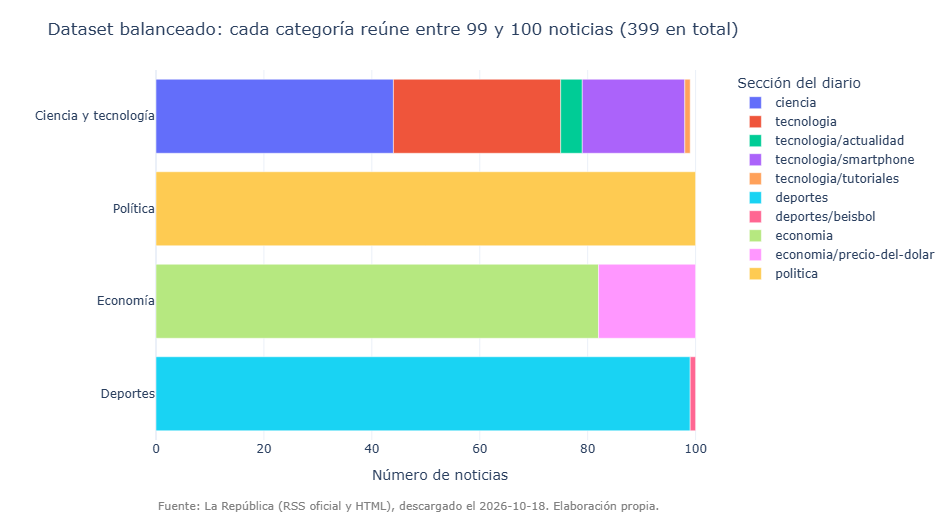

etiqueta
politica              100
economia              100
deportes              100
ciencia_tecnologia     99
Name: count, dtype: int64

In [15]:
por_categoria = (df.groupby(["etiqueta", "seccion_original"]).size().rename("noticias").reset_index())
por_categoria["categoria"] = por_categoria["etiqueta"].map(ETIQUETAS_LEGIBLES)
totales = df["etiqueta"].value_counts()
orden = [ETIQUETAS_LEGIBLES[c] for c in totales.sort_values().index]

if totales.max() / totales.min() <= 1.15:
    titulo = (f"Dataset balanceado: cada categoría reúne entre {totales.min()} y {totales.max()} "
              f"noticias ({len(df)} en total)")
else:
    titulo = (f"{ETIQUETAS_LEGIBLES[totales.idxmax()]} domina con {totales.max()} noticias; "
              f"{ETIQUETAS_LEGIBLES[totales.idxmin()]} queda en {totales.min()}")

fig = px.bar(por_categoria, x="noticias", y="categoria", color="seccion_original", orientation="h",
             category_orders={"categoria": orden}, title=titulo,
             labels={"noticias": "Número de noticias", "categoria": "", "seccion_original": "Sección del diario"})
pie_de_fuente(fig).show()
totales

Las subsecciones muestran la composición interna de cada categoría: en **Ciencia y tecnología** conviven `ciencia` (44) y varias subsecciones de `tecnologia` (55); en **Economía**, 18 de 100 notas son de `precio-del-dolar`, notas casi idénticas día a día que un clasificador aprenderá con facilidad.

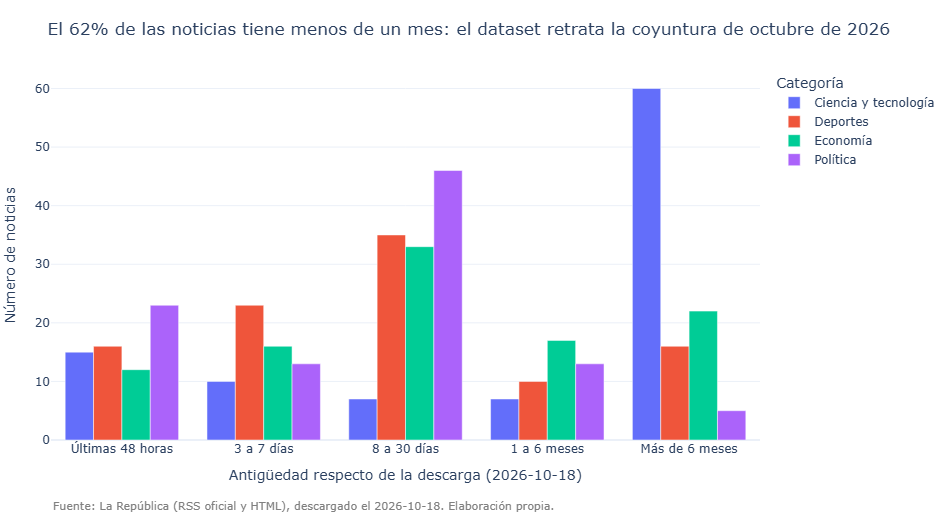

Rango de fechas: 2019-11-20 → 2026-10-18


antiguedad
Últimas 48 horas     66
3 a 7 días           62
8 a 30 días         121
1 a 6 meses          47
Más de 6 meses      103
Name: count, dtype: int64

In [16]:
descarga = pd.Timestamp(metadatos["fecha_descarga"][:10])
dias = (descarga - pd.to_datetime(df["fecha"])).dt.days
cortes = [-1, 2, 7, 30, 180, 10_000]
rangos = ["Últimas 48 horas", "3 a 7 días", "8 a 30 días", "1 a 6 meses", "Más de 6 meses"]
df["antiguedad"] = pd.cut(dias, bins=cortes, labels=rangos)

por_rango = df.groupby(["antiguedad", "etiqueta"], observed=False).size().rename("noticias").reset_index()
por_rango["categoria"] = por_rango["etiqueta"].map(ETIQUETAS_LEGIBLES)
pct_mes = (dias <= 30).mean()
MESES = ["enero", "febrero", "marzo", "abril", "mayo", "junio", "julio", "agosto",
         "septiembre", "octubre", "noviembre", "diciembre"]
titulo = (f"El {pct_mes:.0%} de las noticias tiene menos de un mes: el dataset retrata la coyuntura "
          f"de {MESES[descarga.month - 1]} de {descarga.year}" if pct_mes >= 0.5 else
          f"Solo el {pct_mes:.0%} de las noticias tiene menos de un mes: el dataset mezcla varias coyunturas")

fig = px.bar(por_rango, x="antiguedad", y="noticias", color="categoria", barmode="group", title=titulo,
             labels={"antiguedad": f"Antigüedad respecto de la descarga ({descarga:%Y-%m-%d})",
                     "noticias": "Número de noticias", "categoria": "Categoría"})
pie_de_fuente(fig).show()
print("Rango de fechas:", df["fecha"].min(), "→", df["fecha"].max())
df["antiguedad"].value_counts().reindex(rangos)

**Hallazgo: la antigüedad no es pareja entre categorías.** Política es coyuntura pura (solo 5 notas tienen más de 6 meses), mientras que **60 de las 99 notas de Ciencia y tecnología tienen más de 6 meses**: son notas «atemporales» (tutoriales, reseñas de celulares, curiosidades científicas) que el diario sigue enlazando desde sus páginas. Es un sesgo a vigilar en la Parte 2: el modelo podría asociar «tecnología» con un *estilo* de nota de servicio («¿Cómo…?») más que con el tema.

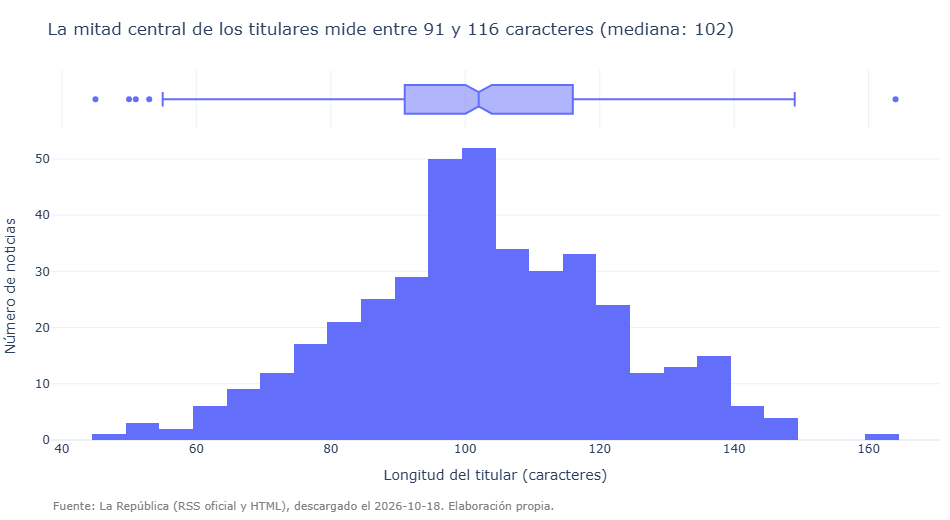

,count,mean,std,min,25%,50%,75%,max
etiqueta,,,,,,,,
ciencia_tecnologia,99.0,103.9,19.1,45.0,91.5,100.0,118.0,164.0
deportes,100.0,111.8,18.9,57.0,99.8,111.5,124.2,149.0
economia,100.0,97.8,17.8,51.0,88.8,99.0,106.0,142.0
politica,100.0,96.3,19.3,50.0,83.0,98.0,111.0,135.0


In [17]:
df["largo_titular"] = df["titular"].str.len()
q1, mediana, q3 = df["largo_titular"].quantile([0.25, 0.5, 0.75]).round().astype(int)

fig = px.histogram(df, x="largo_titular", nbins=30, marginal="box",
                   title=f"La mitad central de los titulares mide entre {q1} y {q3} caracteres (mediana: {mediana})",
                   labels={"largo_titular": "Longitud del titular (caracteres)", "count": "Noticias"})
fig.update_yaxes(title_text="Número de noticias", row=1, col=1)
pie_de_fuente(fig).show()
df.groupby("etiqueta")["largo_titular"].describe().round(1)

La distribución es casi simétrica alrededor de los 100 caracteres. Por categoría, **Deportes tiene los titulares más largos** (mediana 111,5 frente a 98 en Política): suelen juntar equipo, rival, torneo y resultado en una sola línea.

## 5 · Validación: titulares más largos y más cortos

Si el histograma está bien construido, sus extremos deben coincidir con estos casos, y los casos
deben ser titulares reales (no texto cortado ni basura de la página).

In [18]:
columnas_ver = ["largo_titular", "etiqueta", "titular"]
print("5 titulares MÁS LARGOS")
display(df.nlargest(5, "largo_titular")[columnas_ver])
print("5 titulares MÁS CORTOS")
display(df.nsmallest(5, "largo_titular")[columnas_ver])

minimo, maximo = df["largo_titular"].min(), df["largo_titular"].max()
print(f"Extremos del histograma: {minimo} y {maximo} caracteres "
      f"→ coinciden con la tabla: {minimo == df.nsmallest(1, 'largo_titular')['largo_titular'].iloc[0] and maximo == df.nlargest(1, 'largo_titular')['largo_titular'].iloc[0]}")

5 titulares MÁS LARGOS


,largo_titular,etiqueta,titular
43,164,ciencia_tecnologia,"En 1986, la explosión del reactor de Chernóbil obligó a que los perros fueran abandonados por sus dueños; ..."
35,149,deportes,"Pablo Guede ningunea a Franco Velazco, administrador de Universitario, tras polémicas declaraciones en su ..."
587,149,deportes,Jorge Fossati protagonizó tenso cruce con Gonzalo Núñez por episodio durante su etapa en la selección peru...
41,148,deportes,"Mia Shalit, arquera de Universitario, destaca el nivel de las cremas pese a derrota ante Palmeiras por Cop..."
42,147,ciencia_tecnologia,Los lobos gigantes modificados genéticamente pasaron un chequeo médico por sus 2 años: “Ahora podemos ver ...


5 titulares MÁS CORTOS


,largo_titular,etiqueta,titular
516,45,ciencia_tecnologia,¿Cómo usar ClipConverter y qué tan seguro es?
337,50,politica,Fugó cabecilla de la banda que mató a “China Polo”
490,51,economia,Peruanos gastan en promedio S/230 en compras online
378,53,economia,Movistar: Más de 100 comunidades rurales acceden a 4G
505,55,politica,Ejército simuló entrega de helicópteros rusos reparados


Extremos del histograma: 45 y 164 caracteres → coinciden con la tabla: True


**Coherencia con el histograma.** El titular más corto (45 caracteres, «¿Cómo usar ClipConverter y qué tan seguro es?») y el más largo (164, la nota de los perros de Chernóbil) son exactamente los extremos del histograma y los puntos aislados del diagrama de caja. Los diez casos son titulares completos y legibles: no hay texto cortado ni restos de la página.

## 6 · Exportación

Se guardan exactamente las **7 columnas obligatorias**, en el orden pedido.

In [19]:
COLUMNAS = ["titular", "bajada", "medio", "seccion_original", "url", "fecha", "etiqueta"]
noticias = df[COLUMNAS].sort_values(["etiqueta", "fecha"], ascending=[True, False]).reset_index(drop=True)
noticias.to_csv(DATOS / "noticias.csv", index=False)

print("df.shape:", noticias.shape)
print("Bajadas vacías:", (noticias["bajada"] == "").sum(), "· URLs únicas:", noticias["url"].is_unique)
noticias.head(5)

df.shape: (399, 7)
Bajadas vacías: 0 · URLs únicas: True


,titular,bajada,medio,seccion_original,url,fecha,etiqueta
0,Los lobos gigantes modificados genéticamente pasaron un chequeo médico por sus 2 años: “Ahora podemos ver ...,Colossal Biosciences introdujo a estos animales en 2025. Los dos lobos machos ya tienen dos años y su herm...,La Republica,ciencia,https://larepublica.pe/ciencia/2026/10/18/los-lobos-gigantes-modificados-geneticamente-pasaron-un-chequeo-...,2026-10-18,ciencia_tecnologia
1,"En 1986, la explosión del reactor de Chernóbil obligó a que los perros fueran abandonados por sus dueños; ...","Un estudio revela que estos animales cerca de la central nuclear presentaron variantes genéticas, lo que d...",La Republica,ciencia,https://larepublica.pe/ciencia/2026/10/18/en-1986-la-explosion-del-reactor-de-chernobil-obligo-a-que-los-p...,2026-10-18,ciencia_tecnologia
2,Investigadores sudafricanos pintan franjas rojas en las palas de las turbinas eólicas: los resultados sorp...,Esta estrategia ayudaría a hacer más visibles las aspas de los gigantescos aerogeneradores para las aves.,La Republica,ciencia,https://larepublica.pe/ciencia/2026/10/18/investigadores-sudafricanos-pintan-franjas-rojas-en-las-palas-de...,2026-10-18,ciencia_tecnologia
3,En 1993 se liberaron 300 bisontes en una pradera de Oklahoma y ahora deambulan más de 2.000 ayudando a pro...,"Estos grandes mamíferos ayudan a mantener la salud de la pradera mediante el pastoreo, favoreciendo el cre...",La Republica,ciencia,https://larepublica.pe/ciencia/2026/10/18/en-1993-se-liberaron-300-bisontes-en-una-pradera-de-oklahoma-y-a...,2026-10-18,ciencia_tecnologia
4,Desconcertación entre los científicos: la Luna podría haberse formado en tan solo 5 horas,"Nuestro satélite natural podría haberse formado no a lo largo de siglos o miles de años, sino en cuestión ...",La Republica,ciencia,https://larepublica.pe/ciencia/2026/10/18/desconcertacion-entre-los-cientificos-la-luna-podria-haberse-for...,2026-10-18,ciencia_tecnologia


El dataset final cumple el mínimo: **399 filas ≥ 350**, 7 columnas, URLs únicas y ninguna bajada vacía.

## Lo que hicimos

| Paso | Cómo |
|---|---|
| Respetar al medio | `robots.txt` traducido a regex + `User-Agent` + pausa de 1–2 s + máx. 1 reintento |
| Canal oficial | RSS (`/rss/<seccion>.xml`) leído con `BeautifulSoup(..., "xml")` |
| Completar volumen | HTML de páginas de sección y de noticia con `requests` + `BeautifulSoup` |
| Guardar apenas se extrae | `datos/raw/` (robots, XML de cada RSS, `articulos_html.jsonl`, `noticias_crudas.csv`) |
| Limpiar | Duplicados por URL y por titular, titulares vacíos, fechas a `AAAA-MM-DD` (hora de Lima) |
| Etiquetar | Mapeo explícito sección → 4 categorías; lo demás se descarta y se reporta |
| Explorar | 3 gráficos Plotly con título-conclusión + validación de extremos |
| Exportar | `datos/noticias.csv` con 7 columnas |